## Just some basic EDA and a how-to guide. ##

In [ ]:
import torch.nn as nn
import torch
import torch.optim as optim
from pathlib import Path

try:
    import cudf as pd

    BACKEND = "cudf (GPU)"
except Exception:  # ImportError, or CUDA/driver errors on GPU-less machines
    import pandas as pd

    BACKEND = "pandas (CPU)"
DEVICE_PYTORCH= "cuda" if torch.cuda.is_available() else "cpu"

print(f"Using pd={BACKEND}, device_pytorch={DEVICE_PYTORCH}")


# Download latest version

# "magic" command to make plots show up in the notebook
%matplotlib inline 
filepath = Path(
    "/home/vlitoux/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3"
)
dataset_path = filepath / "training_data_validated_vs_rejected.parquet"
print("Path to dataset files:", dataset_path)
print("Existing:", dataset_path.exists())

Using pd=cudf (GPU), device_pytorch=cuda
Path to dataset files: /home/vlitoux/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/training_data_validated_vs_rejected.parquet
Existing: True


Run the python-with-correlation-pca.ipynb notebook to have the parquet file

In [94]:
entire_df: pd.DataFrame = pd.read_parquet(dataset_path)
entire_df.info()

<class 'cudf.core.dataframe.DataFrame'>
Index: 11057781 entries, 0 to 2260698
Data columns (total 6 columns):
 #   Column          Dtype
---  ------          -----
 0   is_accepted     int64
 1   loan_amnt       float64
 2   fico_range_low  float64
 3   dti             float64
 4   emp_length      float64
 5   loan_status     str
dtypes: float64(4), int64(1), str(1)
memory usage: 635.0 MB


In [98]:
from cuml import train_test_split
from cuml.preprocessing import StandardScaler

selected_columns = ["loan_amnt", "fico_range_low", "dti", "emp_length"]

if len(entire_df) > 50000:
    sample_df = entire_df.sample(n=50000, random_state=42)

X = sample_df[selected_columns].values
y = sample_df["is_accepted"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled.shape, X_test_scaled.shape,y_train.shape,y_test.shape

((40000, 4), (10000, 4), (40000,), (10000,))

In [ ]:

class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.network(x)

class LogisticRegression(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        return self.sigmoid(self.linear(x))

In [ ]:
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32, device=DEVICE_PYTORCH)
y_train_t = torch.tensor(y_train, dtype=torch.float32, device=DEVICE_PYTORCH).unsqueeze(1)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32, device=DEVICE_PYTORCH)
y_test_t = torch.tensor(y_test, dtype=torch.float32, device=DEVICE_PYTORCH)
criterion = nn.BCELoss()

input_dim = X_train_t.shape[1]
epochs = 500



X_train_t.device, X_test_t.device, y_train_t.device, y_test_t.device


(device(type='cuda', index=0),
 device(type='cuda', index=0),
 device(type='cuda', index=0),
 device(type='cuda', index=0))

In [10]:
X_train_t.min()

tensor(-7.4782, device='cuda:0')

In [111]:
def f1_score(y_prob, y_true, threshold=0.5, eps=1e-7):
    """
    Binary F1-score from predicted probabilities.
    y_prob : tensor (n, 1) or (n,) with P(class=1), e.g. mlp output after sigmoid
    y_true : tensor of 0/1 labels, any shape broadcastable to y_prob
    """
    y_pred = (y_prob >= threshold).int().view(-1)
    y_true = y_true.int().view(-1)

    tp = (y_pred * y_true).sum().float()
    fp = (y_pred * (1 - y_true)).sum().float()
    fn = ((1 - y_pred) * y_true).sum().float()

    precision = tp / (tp + fp + eps)
    recall    = tp / (tp + fn + eps)
    return 2 * precision * recall / (precision + recall + eps)

### Logistic regression training

In [112]:
lr = LogisticRegression(input_dim=input_dim).to(DEVICE_PYTORCH)
optimizer = optim.Adam(lr.parameters(), lr=0.01)
lr.train()

for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = lr(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

lr.eval()
with torch.no_grad():
    test_probabilities = lr(X_test_t)
    y_pred = (test_probabilities >= 0.5).int().squeeze()
    accuracy = torch.mean((y_pred == y_test_t).float())
    f1 = f1_score(test_probabilities,y_test_t)
print(f"\nLogistic Regression accuracy: {accuracy:.4f}")
print(f"\nLogistic Regression f1_score: {f1:.4f}")


Logistic Regression accuracy: 0.8799

Logistic Regression f1_score: 0.6550


### MLP training

In [113]:
mlp = MLP(input_dim=input_dim).to(DEVICE_PYTORCH)
optimizer = optim.Adam(mlp.parameters(), lr=0.01)
mlp.train()

for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = mlp(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

mlp.eval()
with torch.no_grad():
    test_probabilities = mlp(X_test_t)
    y_pred = (test_probabilities >= 0.5).int().squeeze()
    accuracy = torch.mean((y_pred == y_test_t).float())
    f1 = f1_score(test_probabilities,y_test_t)

print(f"\nMulti Layer Perceptron accuracy: {accuracy:.4f}")
print(f"\nMLP f1_score: {f1:.4f}")


Multi Layer Perceptron accuracy: 0.9384

MLP f1_score: 0.8486


## Evaluate with SHAP

### Initialize and BeeSwarm

We cannot use the traditional Explainer of SHAP, as it is made for scikit-learn type ML models.
`DeepExplainer` is made for neural network

Documentation of Shap DeepExplainer
https://shap.readthedocs.io/en/latest/generated/shap.DeepExplainer.html

In [117]:
import numpy as np
import cupy

NB_SAMPLE=1000
NB_INPUT_FEATURES=4

#Select NB_SAMPLE random training data points
X_train_sample_random = X_train_t[torch.randperm(X_train_t.size(0))[:NB_SAMPLE]]

# Descale the feature to read them on the plot
X_descaled : np.ndarray = cupy.asnumpy(scaler.inverse_transform(X_train_sample_random))

X_descaled.shape,X_train_sample_random.shape

((1000, 4), torch.Size([1000, 4]))

#### Logistic Regression

In [ ]:
import shap

explainer_lr = shap.DeepExplainer(lr, X_train_sample_random)  
shap_values_lr = explainer_lr.shap_values(X_train_sample_random).reshape(NB_SAMPLE,NB_INPUT_FEATURES)  
shap_values_lr.shape

(1000, 4)

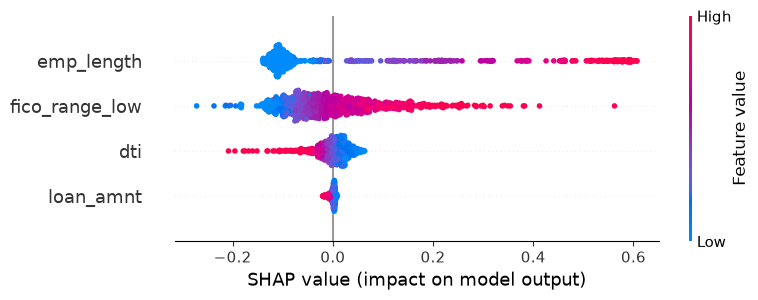

In [ ]:
# Beeswarm for Logistic Regression
shap.summary_plot(shap_values_lr, X_descaled, feature_names=selected_columns)

#### MLP

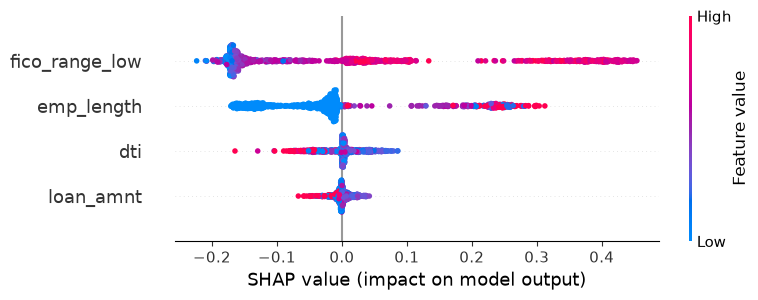

In [ ]:
# Beeswarm for MLP
explainer_mlp = shap.DeepExplainer(mlp, X_train_sample_random)   # background: list of tensors
sv = explainer_mlp.shap_values(X_train_sample_random)                  # tensor input OK here -> (NB_SAMPLE, 4, 1)
shap.summary_plot(sv.reshape(NB_SAMPLE,NB_INPUT_FEATURES),X_descaled, feature_names=selected_columns)

## SHAP scatter dependence for each feature (Only for MLP)

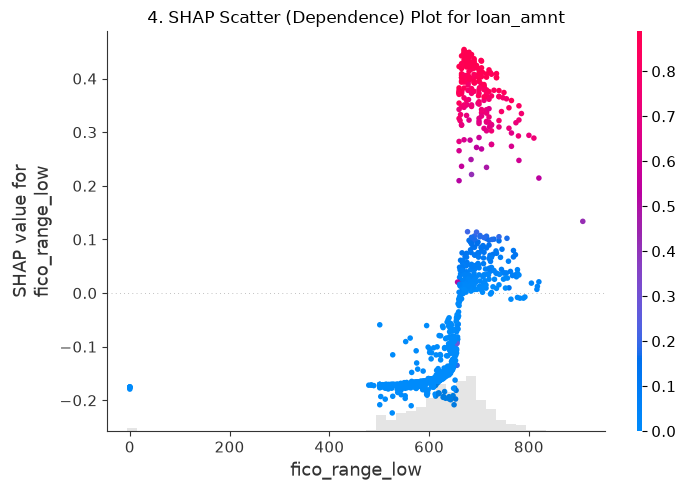

In [ ]:
import matplotlib.pyplot as plt

preds = mlp(X_train_sample_random).detach().cpu().numpy().ravel()   # the single output, shape (100,), values in [0, 1]


exp = shap.Explanation(values=sv, data=X_descaled, feature_names=selected_columns)
shap.plots.scatter(exp[:, "fico_range_low", 0], show=False,color=shap.Explanation(values=preds,data=preds))
plt.title("4. SHAP Scatter (Dependence) Plot for loan_amnt")
plt.tight_layout()
plt.show()

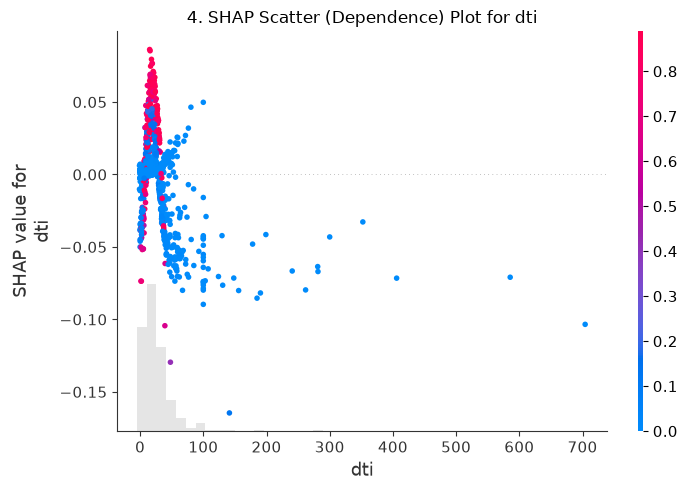

In [89]:
shap.plots.scatter(exp[:, "dti", 0], show=False,color=shap.Explanation(values=preds,data=preds))
plt.title("4. SHAP Scatter (Dependence) Plot for dti")
plt.tight_layout()
plt.show()

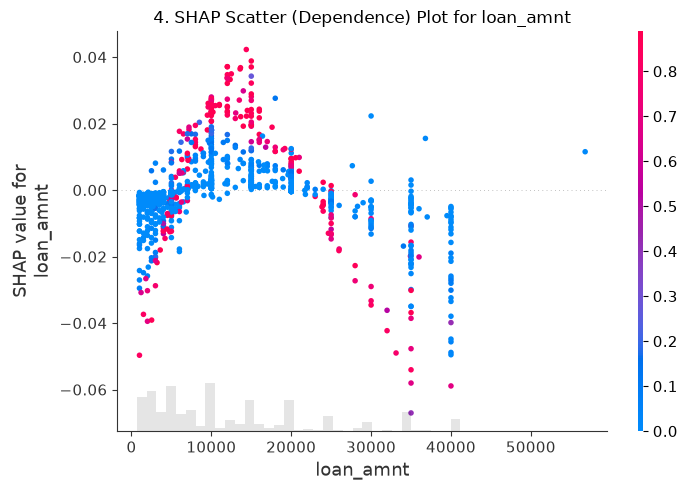

In [90]:
shap.plots.scatter(exp[:, "loan_amnt", 0], show=False,color=shap.Explanation(values=preds,data=preds))
plt.title("4. SHAP Scatter (Dependence) Plot for loan_amnt")
plt.tight_layout()
plt.show()

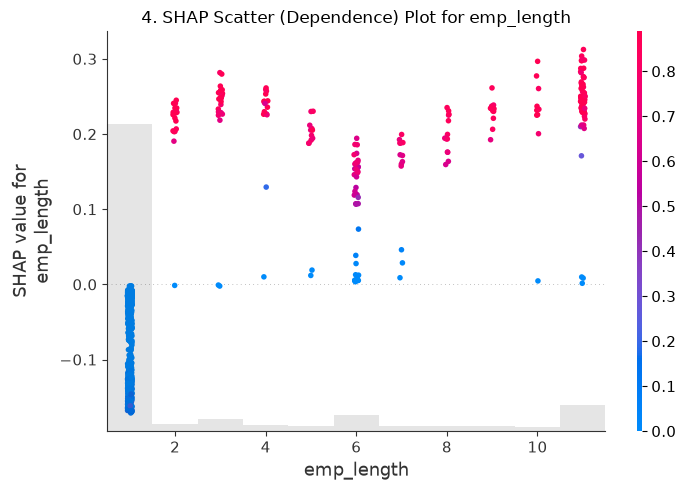

In [91]:
shap.plots.scatter(exp[:, "emp_length", 0], show=False,color=shap.Explanation(values=preds,data=preds))
plt.title("4. SHAP Scatter (Dependence) Plot for emp_length")
plt.tight_layout()
plt.show()